# 14. Reciprocal-Space Momentum Spectrum: $k_\parallel$ Excitation Distribution

## Physical Motivation & Learning Objectives
In diffraction gratings, momentum conservation dictates that transverse momentum is conserved modulo reciprocal lattice vectors:
$$\mathbf{k}_\parallel^{(m)} = \mathbf{k}_\parallel^{(0)} + m \frac{2\pi}{\Lambda} \hat{\mathbf{x}}$$
In this tutorial, we visualize transmitted plane-wave amplitudes in momentum space as a function of normalized in-plane wavevector $k_\parallel / k_0$ using `plotting.t_func_k_plot_1D`.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack


## Simulation Setup


In [2]:
wavelengths = np.linspace(600, 900, 4)
period = 760.0  # nm

light_list = [objects.Light(wl, max_order_PWs=3, theta=15.0, phi=0.0) for wl in wavelengths]

superstrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, world_1d=True, loss=False)
substrate   = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Material(1.45), world_1d=True, loss=False)

grating = objects.NanoStruct(
    '1D_array', period, int(round(0.75 * period)),
    height_nm=1500.0,
    background=materials.Material(1.46),
    inclusion_a=materials.Material(3.61),
    loss=True, lc_bkg=0.01, plt_msh=False
)

def simulate_stack(light):
    sim_sup = superstrate.calc_modes(light)
    sim_sub = substrate.calc_modes(light)
    sim_grt = grating.calc_modes(light, num_BMs=20)
    stk = Stack((sim_sub, sim_grt, sim_sup))
    stk.calc_scat(pol='TE')
    return stk

stacks_list = [simulate_stack(light) for light in light_list]


## $k$-Space Transmitted Order Spectrum


<ipython-input-1-902072ccfdbe>:2: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


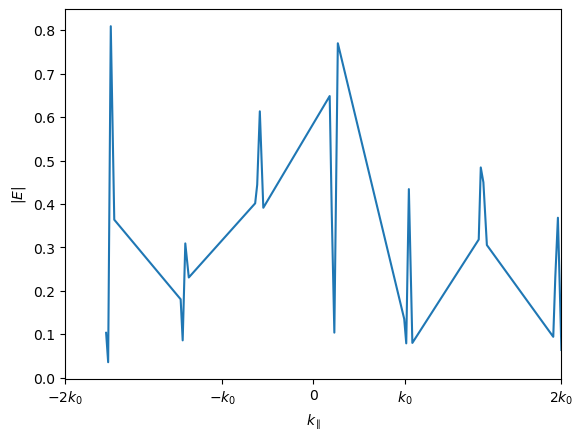

In [3]:
fig_k = plotting.t_func_k_plot_1D(stacks_list, save_pdf=False)
plt.show()


## Physical Interpretation
Diffracted orders with $|k_\parallel| < k_0$ represent propagating radiating waves inside the light cone, whereas orders with $|k_\parallel| > k_0$ decay evanescently away from the grating interfaces.
